# Cross sections — graphite

**NJOY**

Analyze graphite at 293.6 K. TARA uses the reference and three stochastic realizations of the graphite phonon spectrum to calculate and plot the available cross-section channels. Each step identifies its **required inputs** and **optional settings**.

This workflow runs LEAPR and THERMR directly from the template and the base neutron evaluation.

**NCrystal**

Examine how perturbations to the graphite phonon spectrum affect neutron cross sections. The notebook generates a reference and three stochastic spectra, evaluates them with NCrystal, and plots the available channels.

The workflow runs directly from the solid NCMAT. Each step identifies its **required inputs** and **optional settings**.

## 0. Choose the engine

**Required setting**

| Setting | Example value | What it controls |
| --- | --- | --- |
| `ENGINE` | `"ncrystal"` | Select `"njoy"` or `"ncrystal"` for this run. |

After changing the engine, restart the kernel and run all cells.

In [9]:
AVAILABLE_ENGINE = ("njoy", "ncrystal")
AVAILABLE_ENGINE_LABEL = {
    "njoy": "NJOY",
    "ncrystal": "NCrystal"
}

In [10]:
ENGINE = "ncrystal"
if ENGINE not in AVAILABLE_ENGINE:
    raise ValueError('Choose ENGINE = "njoy" or "ncrystal".')
ENGINE_LABEL = AVAILABLE_ENGINE_LABEL[ENGINE]

## 1. Locate TARA

The next cell finds TARA and imports the APIs for the chosen engine.

In [11]:
from pathlib import Path
import os
import shutil
import sys

PROJECT_ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "core" / "config.py").is_file()
     and (path / "processing" / "pipelines" / "ace_pipeline.py").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Start Jupyter inside the TARA repository.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import parallel_execution
from core.config import TaraConfig
from core.data.input_pdos import PhononSpectra
from core.sampler.concrete_samplers import TaraSampler

if ENGINE == "njoy":
    from input_output.leapr.core import LeaprFile
    from input_output.leapr.temperature import resolve_leapr_temperature
elif ENGINE == "ncrystal":
    from input_output.ncrystal.core import NCrystalFile
    import tempfile
    import NCrystal as NC

## 2. Select the required inputs

| Setting | Example value | What it controls |
| --- | --- | --- |
| `BASE_LEAPR_FILE` | `tests/fixtures/input_2.leapr` | NJOY material template. |
| `BASE_NCMAT_FILE` | `tests/fixtures/C_sg194_pyrolytic_graphite.ncmat` | NCrystal graphite template. |
| `BASE_ENDF_FILE` | `tests/fixtures/n_6-C-012g.jeff` | Neutron evaluation for the NJOY path. Override with `TARA_BASE_ENDF` if needed. |
| `NJOY_EXECUTABLE` | `NJOY_EXEC` or `njoy` on `PATH` | Executable for the NJOY path. |

Edit paths only if your checkout or NJOY installation uses different locations.

In [12]:
fixtures = PROJECT_ROOT / "tests" / "fixtures"
BASE_ENDF_FILE = Path(os.environ.get("TARA_BASE_ENDF", str(fixtures / "n_6-C-012g.jeff")))
njoy_path = shutil.which(os.environ.get("NJOY_EXEC") or "njoy")
NJOY_EXECUTABLE = Path(njoy_path) if njoy_path else None

if ENGINE == "njoy":
    if not BASE_ENDF_FILE.is_file() or BASE_ENDF_FILE.stat().st_size == 0:
        raise FileNotFoundError(f"Missing or empty neutron ENDF: {BASE_ENDF_FILE}")
    if NJOY_EXECUTABLE is None:
        raise FileNotFoundError("Set NJOY_EXEC or add njoy to PATH.")

    print("Neutron ENDF:", BASE_ENDF_FILE)
    print("NJOY:", NJOY_EXECUTABLE)

In [13]:
if ENGINE == "njoy":
    BASE_LEAPR_FILE = fixtures / "input_2.leapr"
    if not BASE_LEAPR_FILE.is_file():
        raise FileNotFoundError(f"LEAPR template missing: {BASE_LEAPR_FILE}")

elif ENGINE == "ncrystal":
    BASE_NCMAT_FILE = fixtures / "C_sg194_pyrolytic_graphite.ncmat"
    if not BASE_NCMAT_FILE.is_file():
        raise FileNotFoundError(f"NCMAT template missing: {BASE_NCMAT_FILE}")

## 3. Load the graphite reference

**Fixed settings for this example**

| Setting | Example value | What it controls |
| --- | --- | --- |
| `TEMPERATURE_K` | `293.6` | Evaluation temperature in kelvin. |
| `ATOM_LABEL` | `"C"` | Species supplying the reference spectrum. |

In [14]:
TEMPERATURE_K = 293.6
ATOM_LABEL = "C"
print(f"Engine: {ENGINE_LABEL}")
print(f"temperature: {TEMPERATURE_K:g} K")

if ENGINE == "njoy":
    template = LeaprFile.from_file(str(BASE_LEAPR_FILE))
    leapr_template = template

    resolve_leapr_temperature(template, TEMPERATURE_K, warn_on_reuse=False)
    raw_pdos = template.pdos
    reference_spectrum = PhononSpectra(pdos=raw_pdos)
    print(f"LEAPR file: {BASE_LEAPR_FILE}")
elif ENGINE == "ncrystal":
    material = NCrystalFile.from_file(str(BASE_NCMAT_FILE))
    raw_pdos = material.pdos_for_atom(ATOM_LABEL)
    reference_spectrum = PhononSpectra(pdos=raw_pdos)
    print(f"NCMAT file: {BASE_NCMAT_FILE}")

Engine: NCrystal
temperature: 293.6 K
NCMAT file: /home/aitor/postdoc/tara_preview_V3_5/tests/fixtures/C_sg194_pyrolytic_graphite.ncmat


## 4. Sample the vibrational spectrum

**Required:** The PDOS from Section 3 and the two perturbation bounds below. Select a positive sample count for the comparison.

**Required sampling settings**

| Setting | Example value | What it controls |
| --- | --- | --- |
| `MAX_ENERGY_SHIFT_MEV` | `1.0` | Maximum phonon-energy displacement in meV. |
| `MAX_AMPLITUDE_SHIFT_PCT` | `5.0` | Maximum relative PDOS amplitude change in percent. |
| `N_SAMPLES` | `3` | Number of stochastic samples. The reference is stored separately. |

In [15]:
MAX_ENERGY_SHIFT_MEV = 1.0
MAX_AMPLITUDE_SHIFT_PCT = 5.0
N_SAMPLES = 3

**Optional sampling settings**

| Setting | Example value | What it controls |
| --- | --- | --- |
| `RANDOM_SEED` | `20261008` | Seed for reproducible sampling. |
| `BATCH_SIZE` | `512` | Internal sampling chunk size. |
| `AMPLITUDE_METHOD` | `"fast"` | Method used for the amplitude perturbations. |
| `SPATIAL_METHOD` | `"diffeomorphic"` | Method used to shift the spectrum in energy. |

In [16]:
RANDOM_SEED = 20261008
BATCH_SIZE = 512
AMPLITUDE_METHOD = "fast"
SPATIAL_METHOD = "diffeomorphic"

In [ ]:
# Validate all perturbation bounds and sampling strategies using TaraConfig.
configuration = TaraConfig(
    max_energy_shift_mev=MAX_ENERGY_SHIFT_MEV,
    max_amplitude_shift_pct=MAX_AMPLITUDE_SHIFT_PCT,
    n_samples=N_SAMPLES,
    random_seed=RANDOM_SEED,
)

# Initialize TaraSampler with the selected amplitude and spatial methods.
sampler = TaraSampler(
    config=configuration,
    spectra=reference_spectrum,
    amplitude_method=AMPLITUDE_METHOD,
    spatial_method=SPATIAL_METHOD,
)

# Generate the stochastic ensemble with the configured sampling batch size.
ensemble = sampler.generate_ensemble(batch_size=BATCH_SIZE)
if ensemble.reference is None or len(ensemble) != N_SAMPLES:
    raise RuntimeError("Expected the reference and all requested samples.")
print(f"Prepared one reference and {len(ensemble)} stochastic spectra.")

Prepared one reference and 3 stochastic spectra.


## 5. Configure the Analyzer and request cross sections

**NJOY**

**Required:** The material from Section 3 and the ensemble from Section 4. The NJOY Analyzer runner uses the LEAPR template and the neutron evaluation. The target mass is derived from the LEAPR principal-atom mass ratio.

**Optional settings:** All samples are selected. Adjust the observable settings below or the optional THERMR settings in Section 6.

**NCrystal**

**Required:** The material file and temperature from Section 3 and the ensemble from Section 4. The NCrystal runner evaluates the material, while the parser extracts cross sections for the Analyzer.

**Optional settings:** The Analyzer uses all samples. The energy grid and channel selections are defined in the observable settings below.

In [18]:
import numpy as np
from analyzer.ensemble_analyzer import EnsembleAnalyzer

if ENGINE == "njoy":
    from endf_parserpy import EndfParserPy
    from scipy.constants import physical_constants
    from analyzer.parsers.njoy_parser import NjoyParser
    from analyzer.runners.njoy_runner import NjoyRunner

    base_header = EndfParserPy().parsefile(str(BASE_ENDF_FILE), include=[1])[1][451]
    if int(round(float(base_header["ZA"]))) != 6012:
        raise ValueError("Expected base neutron evaluation ZA=6012.")
    MASS_AMU = float(template.principal_scatterer["awr"]) * physical_constants["neutron mass in u"][0]
elif ENGINE == "ncrystal":
    from analyzer.parsers.ncrystal_parser import NCrystalParser
    from analyzer.runners.ncrystal_runner import NCrystalRunner

In [19]:
# Configure the appropriate engine runner and parser based on the selected ENGINE.
if ENGINE == "njoy":
    runner = NjoyRunner(
        njoy_exec=str(NJOY_EXECUTABLE),
        base_endf_file=str(BASE_ENDF_FILE),
        base_leapr_file=str(BASE_LEAPR_FILE),
        temperature=TEMPERATURE_K,
        mass_amu=MASS_AMU,
    )
    parser = NjoyParser()
elif ENGINE == "ncrystal":
    runner = NCrystalRunner(
        base_ncmat_file=str(BASE_NCMAT_FILE),
        temperature=TEMPERATURE_K,
    )
    parser = NCrystalParser()

In [20]:
# Initialize the ensemble analyzer with the generated ensemble, runner, and parser.
analyzer = EnsembleAnalyzer(
    ensemble=ensemble,
    runner=runner,
    parser=parser
)

**Optional observable settings**

**NJOY**

Cross sections are in **barns** and incident neutron energies are in **eV**. The NJOY parser reports the available THERMR thermal-scattering total and its components. Its total excludes absorption. Separate elastic channels are shown when THERMR and MF7 identify them.

**NCrystal**

Cross sections are evaluated in **barns** on an incident neutron energy grid in **eV**. NCrystal's `xs_total` is the total scattering cross section. Absorption is reported separately.

| Setting | Example value | What it controls |
| --- | --- | --- |
| `EVAL_ENERGY_GRID` | `np.geomspace(1e-5, 1.0, 180)` | **NJOY** Incident neutron energies used to report the selected channels.<br>**NCrystal** Incident neutron energies at which to evaluate the selected channels. |
| `calc_xs_total` | `True` | **NJOY** Total thermal scattering available from THERMR.<br>**NCrystal** Total scattering. |
| `calc_xs_inelastic` | `True` | **NJOY** Thermal inelastic scattering.<br>**NCrystal** Inelastic scattering. |
| `calc_xs_elastic` | `True` | **NJOY** Available coherent or incoherent elastic scattering.<br>**NCrystal** Coherent and incoherent elastic scattering as separate channels. |
| `calc_xs_absorption` | `True` | **NCrystal**. Absorption. |

In [21]:
EVAL_ENERGY_GRID = np.geomspace(1e-5, 1.0, 180)

parser_kwargs = dict(
    energy_grid=EVAL_ENERGY_GRID,
    calc_xs_total=True,
    calc_xs_inelastic=True,
    calc_xs_elastic=True,
)

if ENGINE == "ncrystal":
    parser_kwargs["calc_xs_absorption"] = True

## 6. Run the Analyzer

**NJOY**

**Required:** The Analyzer and observable settings from Section 5. Evaluate the reference separately to enable the relative comparisons in Section 7.

**Optional execution and THERMR settings:**

| Setting | Example value | What it controls |
| --- | --- | --- |
| `RUN_PARALLEL` | `False` | Run sequentially or request concurrent processing. |
| `thermr_emax` | `5.0` | Upper THERMR processing energy in eV. |
| `thermr_tol` | `0.05` | THERMR interpolation tolerance. |
| `thermr_nbin` | `16` | THERMR angular bin count. |

**NCrystal**

**Required:** The Analyzer and observable settings from Section 5, and the atom label selected in Section 3. Evaluate the separate reference to enable the relative comparisons in Section 7.

**Optional:** Set `RUN_PARALLEL=True` to request concurrent processing. The example runs sequentially.

In [22]:
RUN_PARALLEL = False

if ENGINE == "njoy":
    RUNNER_OPTIONS = {
        "thermr_emax": 5.0,
        "thermr_tol": 0.05,
        "thermr_nbin": 16,
    }
elif ENGINE == "ncrystal":
    RUNNER_OPTIONS = {"atom_label": ATOM_LABEL}

In [23]:
# Compute the ensemble results using the configured analyzer.
analyzer.compute(
    parallel=RUN_PARALLEL,
    runner_kwargs=RUNNER_OPTIONS,
    parser_kwargs=parser_kwargs,
    compute_reference=True,
)

if analyzer.reference_result is None or len(analyzer.raw_results) != len(ensemble):
    raise RuntimeError("The Analyzer did not return the expected reference and sample results.")
print(f"Analyzed one reference and {len(analyzer.raw_results)} stochastic spectra.")

Analyzed one reference and 3 stochastic spectra.


## 7. Plot the cross sections

**Required:** The reference and sample results from Section 6. Each plot shows the phonon spectra (energy in meV), the cross section (barns versus incident energy in eV), and the percentage difference from the reference:
$100,(sigma_{mathrm{sample}}-sigma_{mathrm{ref}})/sigma_{mathrm{ref}}$.

**Optional settings:** None. To change which channels are calculated, return to Section 5.

The plotting cell skips unavailable channels. Relative differences are undefined wherever the reference cross section is zero.

In [24]:
import matplotlib.pyplot as plt
from notebooks.tara_plotting import plot_master_dashboard

if ENGINE == "njoy":
    def show_cross_section_channel(channel, label):
        """Plot a channel when both reference and sample data are available."""
        reference = getattr(analyzer.reference_result.integ, channel)
        if reference is None or not any(
            getattr(result.integ, channel) is not None for result in analyzer.raw_results
        ):
            print(f"{label}: unavailable for this calculation.")
            return

        plot_master_dashboard(
            data_obj=analyzer,
            ref_label=f"{ENGINE_LABEL} reference",
            pdos_title="Reference and stochastic PDOS",
            main_title=label,
            xs_type=channel,
            plot_pdos=True,
            plot_xs=True,
            plot_error=True,
        )
        plt.show()
elif ENGINE == "ncrystal":
    def show_cross_section_channel(channel, label):
        """Plot a channel when both reference and sample data are available."""
        reference = getattr(analyzer.reference_result.integ, channel)
        if reference is None or not any(
            getattr(result.integ, channel) is not None for result in analyzer.raw_results
        ):
            print(f"{label}: unavailable for this calculation.")
            return

        plot_master_dashboard(
            data_obj=analyzer,
            ref_label=f"{ENGINE_LABEL} reference",
            pdos_title="Reference PDOS and stochastic spectra",
            main_title=label,
            xs_type=channel,
            plot_pdos=True,
            plot_xs=True,
            plot_error=True,
        )
        plt.show()

### 7.1. Total thermal scattering cross section

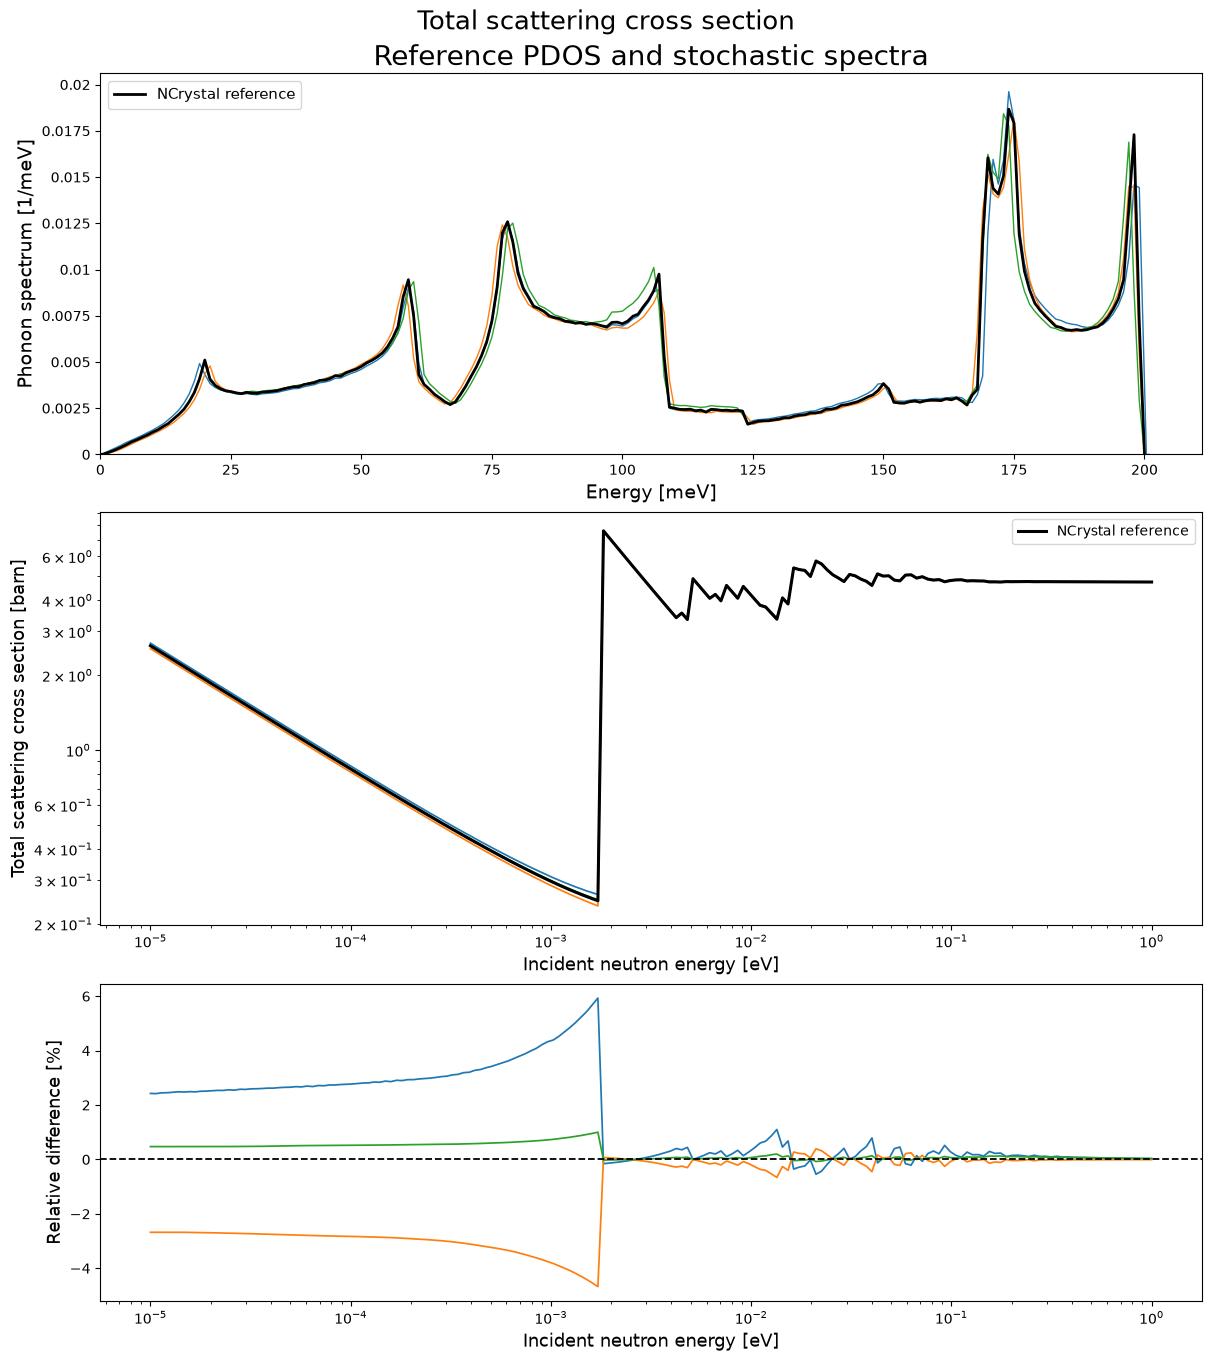

In [25]:
if ENGINE == "njoy":
    total_label = "Total thermal scattering cross section"
elif ENGINE == "ncrystal":
    total_label = "Total scattering cross section"

show_cross_section_channel("xs_total", total_label)

### 7.2. Inelastic scattering cross section

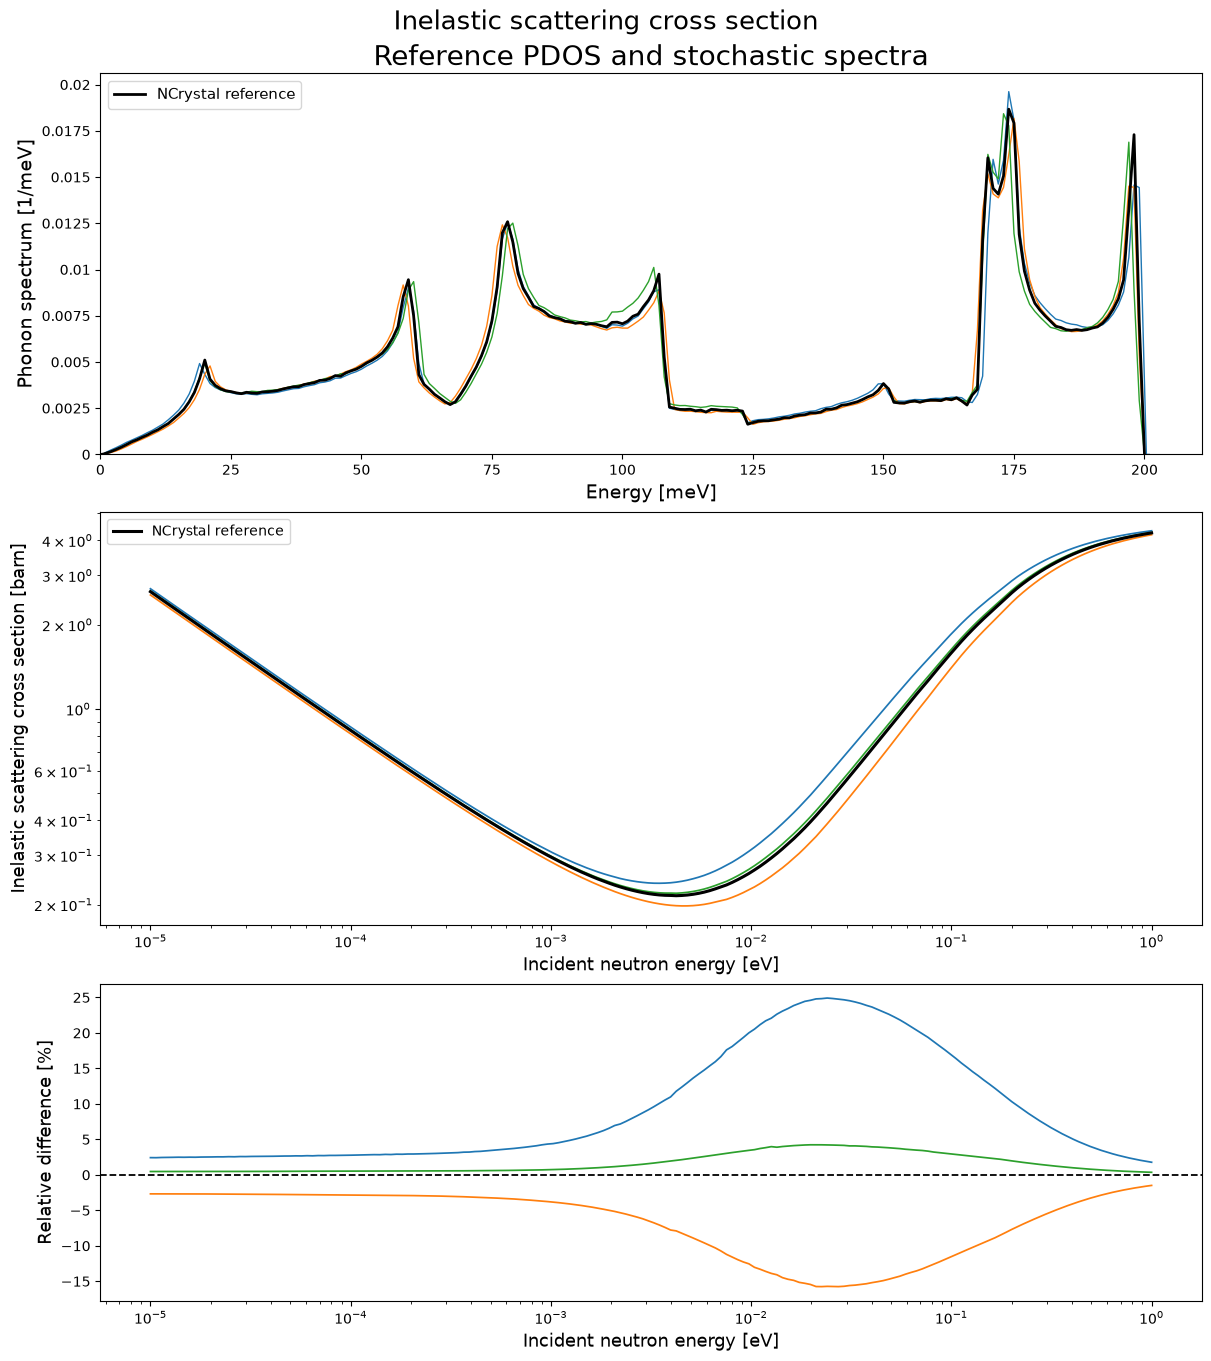

In [26]:
show_cross_section_channel("xs_inelastic", "Inelastic scattering cross section")

### 7.3. Coherent-elastic scattering cross section

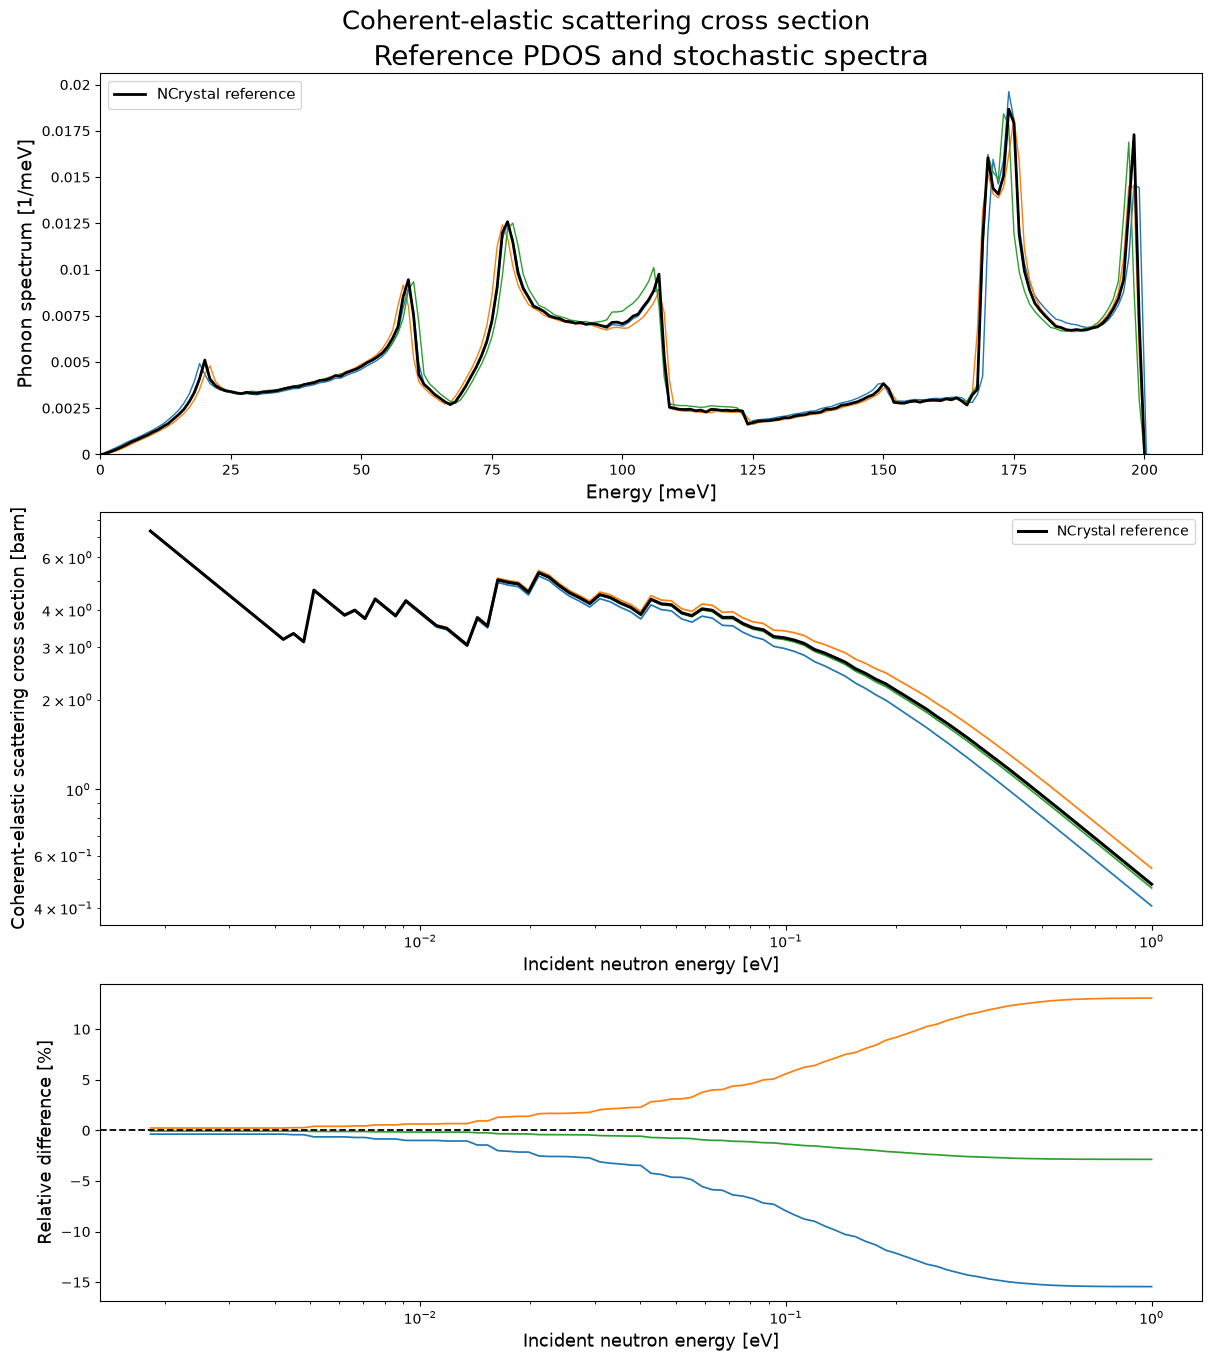

In [27]:
show_cross_section_channel("xs_coherent_elastic", "Coherent-elastic scattering cross section")